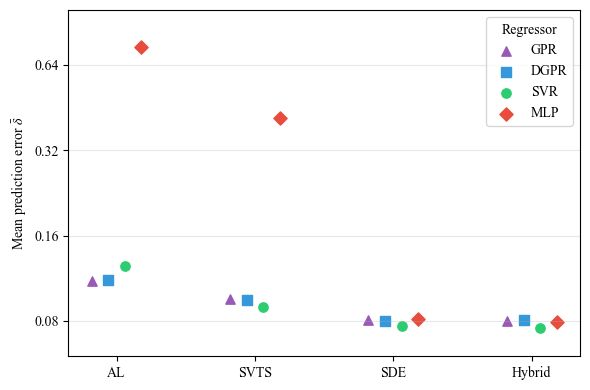

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "STIXGeneral"],
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42,
    }
)

methods = ["AL", "SVTS", "SDE", "Hybrid"]
err = {
    "GPR": [0.110601, 0.095373, 0.080419, 0.07982],
    "DGPR": [0.111852, 0.094651, 0.079751, 0.08028],
    "SVR": [0.124783, 0.089558, 0.076953, 0.07532],
    "MLP": [0.737813, 0.417485, 0.081368, 0.07928],
}
marks = {"GPR": "^", "DGPR": "s", "SVR": "o", "MLP": "D"}
colors = {"GPR": "#9B59B6", "DGPR": "#3498DB", "SVR": "#2ECC71", "MLP": "#E74C3C"}

fig, ax = plt.subplots(figsize=(6, 4))
for i, (name, y) in enumerate(err.items()):
    ax.scatter(
        np.arange(4) + (i - 1.5) * 0.12,
        y,
        marker=marks[name],
        s=45,
        label=name,
        c=colors[name],
    )
ax.set_yscale("log")
ticks = [0.04, 0.08, 0.16, 0.32, 0.64, 1.28]
ax.set_yticks(ticks, ticks)
ax.set_ylim(0.06, 1.0)
ax.minorticks_off()
ax.set_xticks(range(4), methods)
ax.set_ylabel(r"Mean prediction error $\bar{\delta}$")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Regressor")
fig.tight_layout()
fig.savefig("regressor_comparison.pdf")


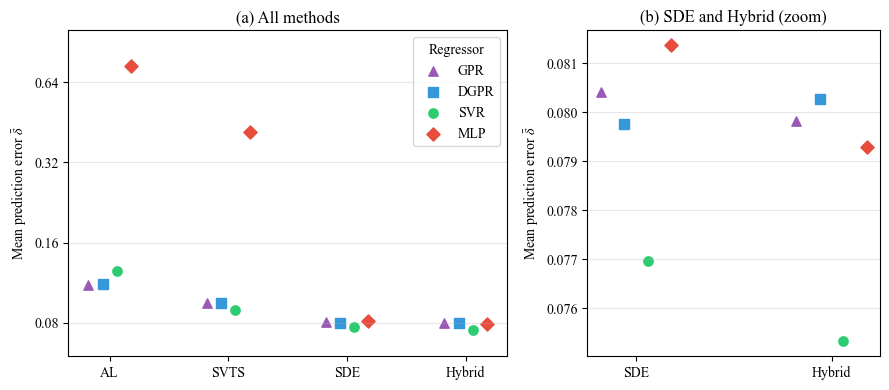

In [9]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "STIXGeneral"],
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42,
    }
)

methods = ["AL", "SVTS", "SDE", "Hybrid"]
err = {
    "GPR": [0.110601, 0.095373, 0.080419, 0.07982],
    "DGPR": [0.111852, 0.094651, 0.079751, 0.08028],
    "SVR": [0.124783, 0.089558, 0.076953, 0.07532],
    "MLP": [0.737813, 0.417485, 0.081368, 0.07928],
}
marks = {"GPR": "^", "DGPR": "s", "SVR": "o", "MLP": "D"}
colors = {"GPR": "#9B59B6", "DGPR": "#3498DB", "SVR": "#2ECC71", "MLP": "#E74C3C"}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4), gridspec_kw={"width_ratios": [3, 2]})
for ax, idx in ((a1, range(4)), (a2, [2, 3])):
    for i, (name, y) in enumerate(err.items()):
        ax.scatter(
            np.arange(len(idx)) + (i - 1.5) * 0.12,
            [y[j] for j in idx],
            marker=marks[name],
            s=45,
            label=name,
            c=colors[name],
        )
    ax.set_xticks(range(len(idx)), [methods[j] for j in idx])
    ax.grid(axis="y", alpha=0.3)
a1.set_yscale("log")
ticks = [0.04, 0.08, 0.16, 0.32, 0.64, 1.28]
a1.set_yticks(ticks, ticks)
a1.set_ylim(0.06, 1.0)
a1.minorticks_off()
a1.set_ylabel(r"Mean prediction error $\bar{\delta}$")
a1.legend(title="Regressor")
a1.set_title("(a) All methods")
a2.set_ylabel(r"Mean prediction error $\bar{\delta}$")
a2.set_title("(b) SDE and Hybrid (zoom)")
fig.tight_layout()
fig.savefig("regressor_comparison_zoom.pdf")
